In [1]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Conv2D, MaxPooling2D, Dropout
import matplotlib.pyplot as plt
import numpy as np
import random

In [2]:
mnist = tf.keras.datasets.mnist
(x_train, y_train) , (x_test, y_test) = mnist.load_data()
input_shape = (28, 28, 1)

In [3]:
x_train = x_train.reshape(x_train.shape[0], 28, 28, 1)
x_test = x_test.reshape(x_test.shape[0], 28, 28, 1) 

print('data type of x_train', x_train.dtype)
x_train = x_train.astype('float32')
x_test = x_test.astype('float32')
print('data type after converting to float', x_train.dtype)
x_train = x_train / 255.0
x_test = x_test / 255.0
print('shape of training:', x_train.shape)
print('shape of testing:', x_test.shape)

data type of x_train uint8
data type after converting to float float32
shape of training: (60000, 28, 28, 1)
shape of testing: (10000, 28, 28, 1)


In [4]:
model = Sequential()
model.add(Conv2D(28, kernel_size = (3, 3), input_shape = input_shape))
model.add(MaxPooling2D(pool_size = (2, 2)))
model.add(Flatten())
model.add(Dense(200 , activation = 'relu'))
model.add(Dropout(0.3))
model.add(Dense(10, activation = 'softmax'))
    

/Users/gayatriapte/work/installer/python312/anaconda3/envs/cnn-env/lib/python3.12/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [5]:
model.compile(optimizer = 'adam', loss = 'sparse_categorical_crossentropy', metrics = ['accuracy'])
model.fit(x_train , y_train, epochs = 5)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9395 - loss: 0.2008
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9747 - loss: 0.0824
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9818 - loss: 0.0577
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9860 - loss: 0.0439
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9887 - loss: 0.0348


313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9863 - loss: 0.0482
Loss=0.048
Accuracy=0.986


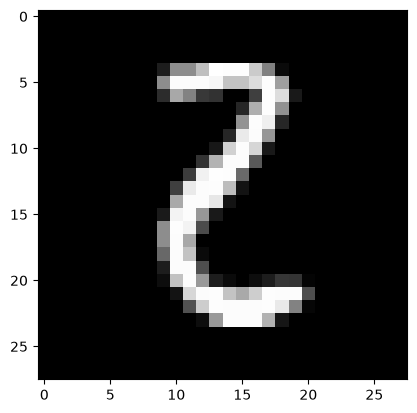

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
predicted class is : 2


/Users/gayatriapte/work/installer/python312/anaconda3/envs/cnn-env/lib/python3.12/site-packages/keras/src/models/functional.py:259: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor
Received: inputs=('Tensor(shape=(1, 28, 28, 1))',)
  warnings.warn(msg)


In [6]:
test_loss, test_acc = model.evaluate(x_test , y_test)
print('Loss=%.3f' %test_loss)
print('Accuracy=%.3f' %test_acc)

idx = random.randint(1, len(x_test))
image = x_test[idx]
plt.imshow(np.squeeze(image), cmap = 'gray')
plt.show()

image = image.reshape(1, image.shape[0], image.shape[1], image.shape[2])
pred = model.predict([image])
print('predicted class is : {}'.format(np.argmax(pred)))